# Сегментный анализ: кому письмо помогает сильнее всего

**Часть 2.** В первой части мы выяснили, что оба письма в среднем повышают визиты, конверсию и траты.
Но «в среднем» скрывает различия: для одних клиентов письмо работает сильно, для других слабо или вообще не работает.

Здесь мы:
1. Делим клиентов на сегменты по известным признакам
2. Считаем эффект каждого письма в каждом сегменте
3. Проверяем, что различия между сегментами реальные, а не случайный шум
4. Формулируем, кому письмо отправлять стоит, а кому нет

Результаты станут основой для uplift-модели в следующей части.

In [5]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

paths = glob.glob("/kaggle/input/**/*Hillstrom*.csv", recursive=True) \
     or glob.glob("/kaggle/input/**/*.csv", recursive=True) \
     or glob.glob("../archive/*.csv")
df = pd.read_csv(paths[0])
print("Файл:", paths[0], df.shape)

CONTROL = "No E-Mail"
TREATMENTS = ["Mens E-Mail", "Womens E-Mail"]

Файл: /kaggle/input/datasets/sumittarya/hillstrom-email-marketing/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv (64000, 12)


## 1. Сегменты

Используем признаки, известные до рассылки. Непрерывные признаки разбиваем на понятные группы.

| Признак | Сегменты |
|---|---|
| `newbie_label` | новый или существующий клиент |
| `channel` | где клиент покупает: Web, Phone, Multichannel |
| `zip_code` | тип района: Urban, Suburban, Rural |
| `history_segment` | сумма покупок за прошлый год (6 уровней) |
| `recency_bucket` | давность последней покупки в месяцах (1–3, 4–6, 7–9, 10–12) |
| `buyer_type` | что покупал: только мужское, только женское, и то и другое |

In [6]:
df["newbie_label"] = df["newbie"].map({0: "existing", 1: "new"})
df["recency_bucket"] = pd.cut(df["recency"], [0, 3, 6, 9, 12], labels=["1-3", "4-6", "7-9", "10-12"])
df["buyer_type"] = np.select(
    [(df.mens == 1) & (df.womens == 0), (df.mens == 0) & (df.womens == 1), (df.mens == 1) & (df.womens == 1)],
    ["only_mens", "only_womens", "both"],
    default="neither",
)

DIMS = ["newbie_label", "channel", "zip_code", "history_segment", "recency_bucket", "buyer_type"]

for dim in DIMS:
    counts = df.groupby(dim, observed=True).size().rename("клиентов")
    print(dim); display(counts.to_frame().T)

newbie_label


newbie_label,existing,new
клиентов,31856,32144


channel


channel,Multichannel,Phone,Web
клиентов,7762,28021,28217


zip_code


...

history_segment,1) $0 - $100,2) $100 - $200,3) $200 - $350,4) $350 - $500,5) $500 - $750,"6) $750 - $1,000","7) $1,000 +"
клиентов,22970,14254,12289,6409,4911,1859,1308


recency_bucket


recency_bucket,1-3,4-6,7-9,10-12
клиентов,22393,14192,14014,13401


buyer_type


buyer_type,both,only_mens,only_womens
клиентов,6448,28818,28734


## 2. Эффект письма в каждом сегменте

Для каждого сегмента считаем разницу «письмо минус контроль» по трём метрикам: визиты, конверсия, траты на клиента.
Разницу в долях показываем в процентных пунктах, в тратах в долларах. К каждому значению добавляем 95%-й доверительный интервал.

Сегментов много, поэтому проверок тоже много. Чем больше проверок, тем выше шанс найти «значимый» эффект случайно.
Чтобы не обмануть себя, применяем **поправку Бенджамини-Хохберга (контроль доли ложных открытий, FDR)**: в таблице колонка `q-value` содержит p-value после поправки.

In [7]:
MIN_N = 200  # слишком маленькие сегменты не анализируем

def segment_effects(metric, treat):
    scale = 100 if metric in ("visit", "conversion") else 1
    rows = []
    for dim in DIMS:
        for val, d in df.groupby(dim, observed=True):
            t = d.loc[d.segment == treat, metric]
            c = d.loc[d.segment == CONTROL, metric]
            if len(t) < MIN_N or len(c) < MIN_N:
                continue
            diff = t.mean() - c.mean()
            se = np.sqrt(t.var(ddof=1) / len(t) + c.var(ddof=1) / len(c))
            p = 2 * stats.norm.sf(abs(diff / se))
            rows.append({
                "признак": dim, "сегмент": str(val), "n_тест": len(t), "n_контроль": len(c),
                "контроль": c.mean() * scale, "тест": t.mean() * scale,
                "эффект": diff * scale, "CI95 низ": (diff - 1.96 * se) * scale, "CI95 верх": (diff + 1.96 * se) * scale,
                "p-value": p,
            })
    res = pd.DataFrame(rows)
    res["q-value"] = multipletests(res["p-value"], method="fdr_bh")[1]
    res["значимо (FDR 5%)"] = res["q-value"] < 0.05
    return res

results = {(m, t): segment_effects(m, t) for m in ["visit", "conversion", "spend"] for t in TREATMENTS}

In [8]:
def forest(res, title, unit):
    r = res.copy()
    r["label"] = r["признак"] + " = " + r["сегмент"]
    r = r.iloc[::-1].reset_index(drop=True)
    colors = np.where(r["значимо (FDR 5%)"], "#4c78a8", "#b0b0b0")
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(r) + 1.5))
    ax.errorbar(r["эффект"], range(len(r)),
                xerr=[r["эффект"] - r["CI95 низ"], r["CI95 верх"] - r["эффект"]],
                fmt="none", ecolor="#999", capsize=2, zorder=1)
    ax.scatter(r["эффект"], range(len(r)), c=colors, zorder=2)
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r["label"])
    ax.set_xlabel(unit); ax.set_title(title + "  (синий: значимо после поправки FDR)")
    plt.tight_layout(); plt.show()

names = {"visit": "Визиты", "conversion": "Конверсия", "spend": "Траты на клиента"}
units = {"visit": "Эффект, п.п.", "conversion": "Эффект, п.п.", "spend": "Эффект, $ на клиента"}

### Конверсия

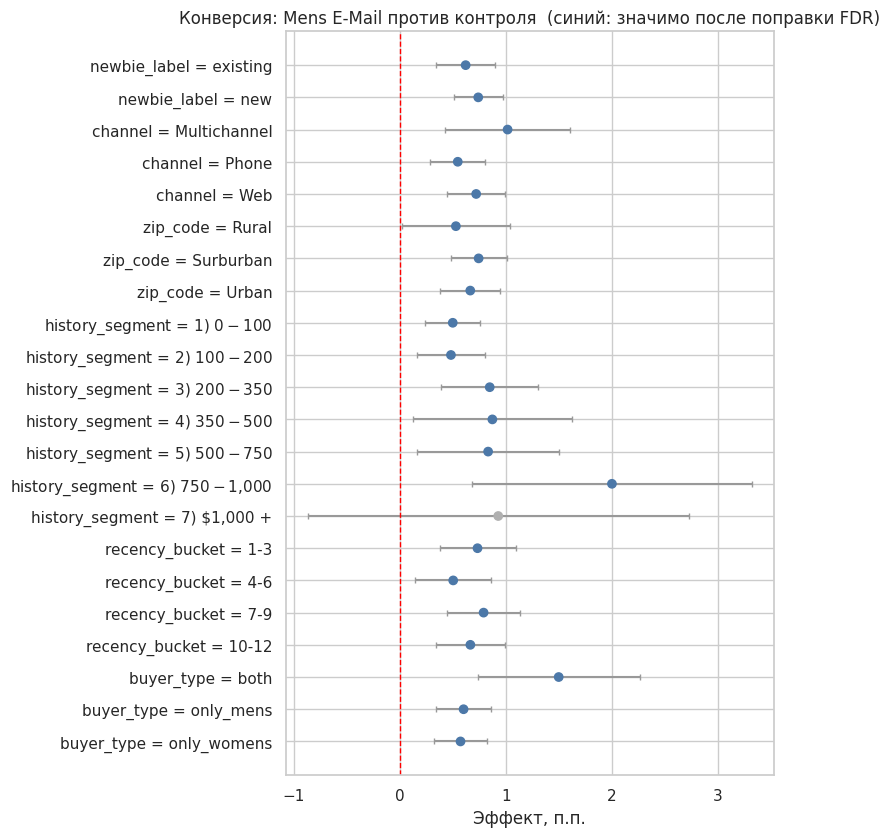

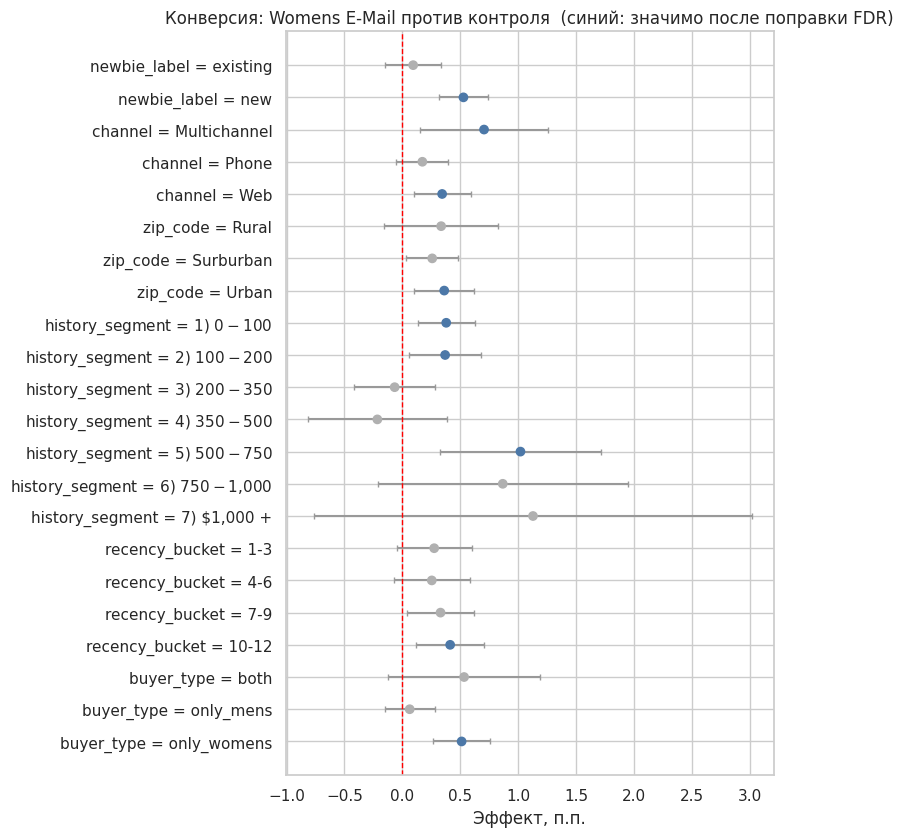

In [9]:
for t in TREATMENTS:
    forest(results[("conversion", t)], f"{names['conversion']}: {t} против контроля", units["conversion"])

### Визиты
Визиты случаются в 15–20 раз чаще покупок, поэтому оценки точнее и различия между сегментами видны лучше.

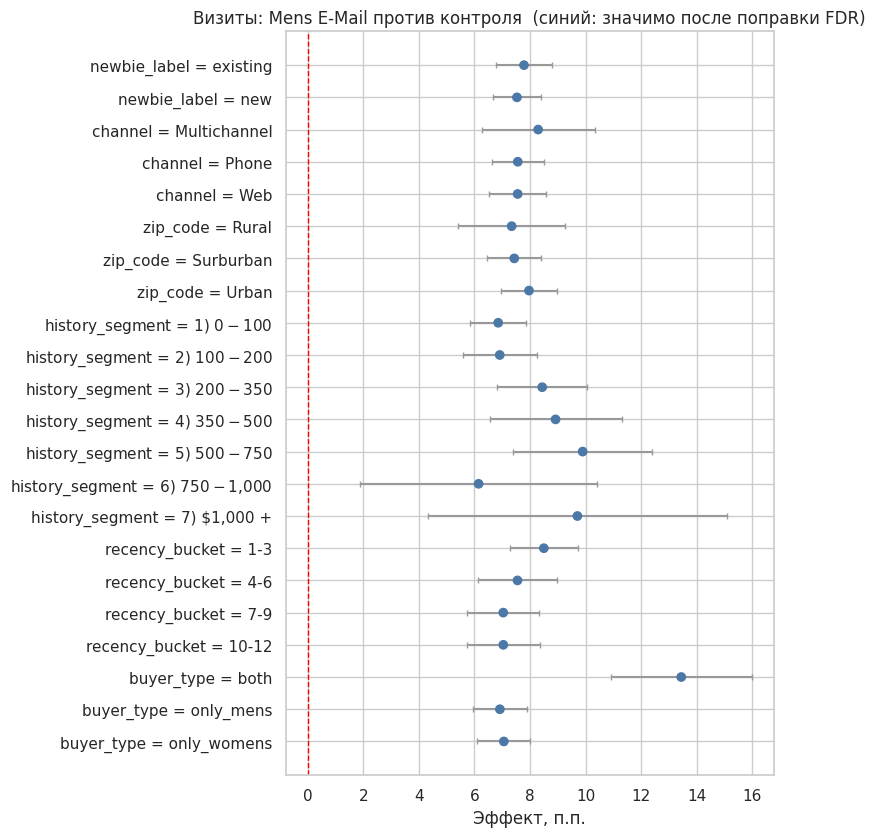

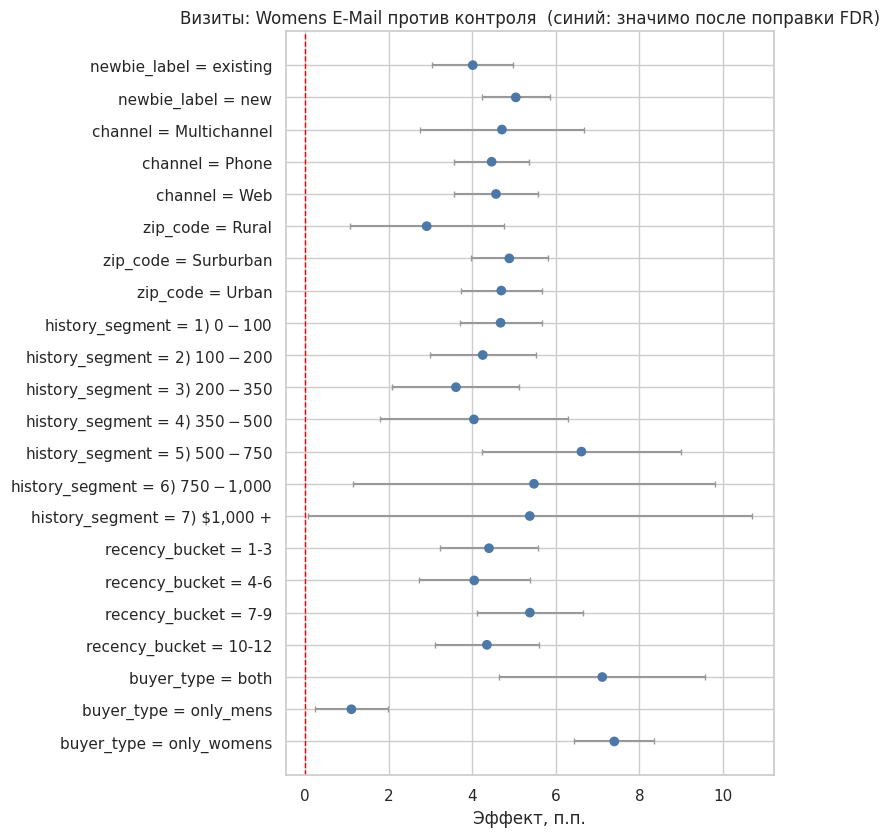

In [10]:
for t in TREATMENTS:
    forest(results[("visit", t)], f"{names['visit']}: {t} против контроля", units["visit"])

### Траты

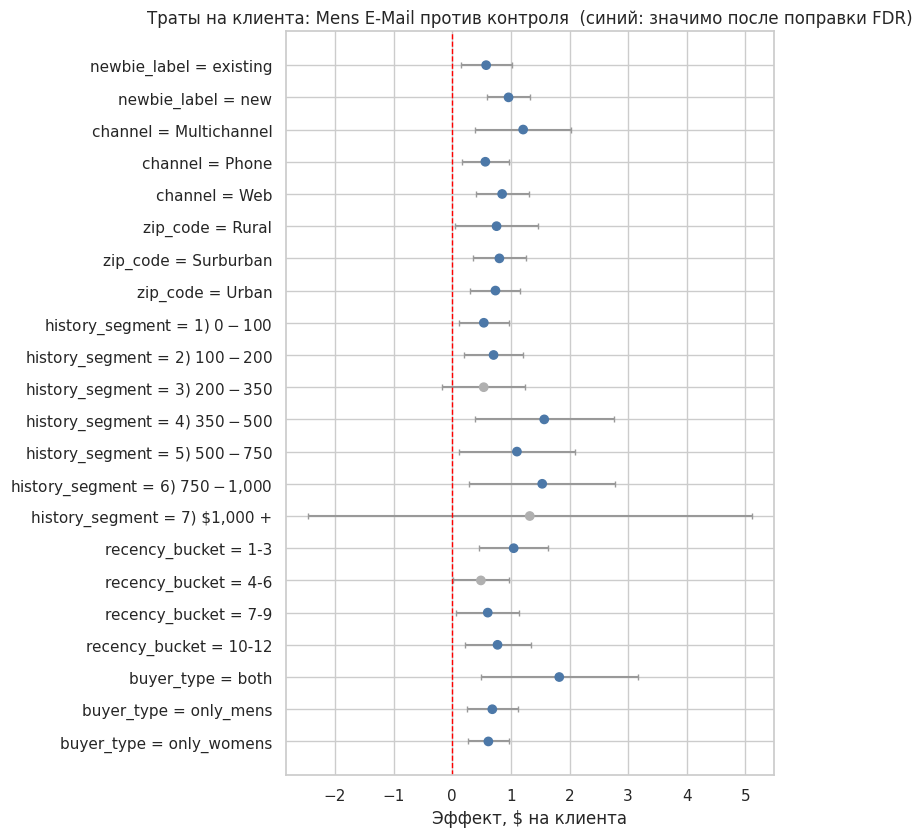

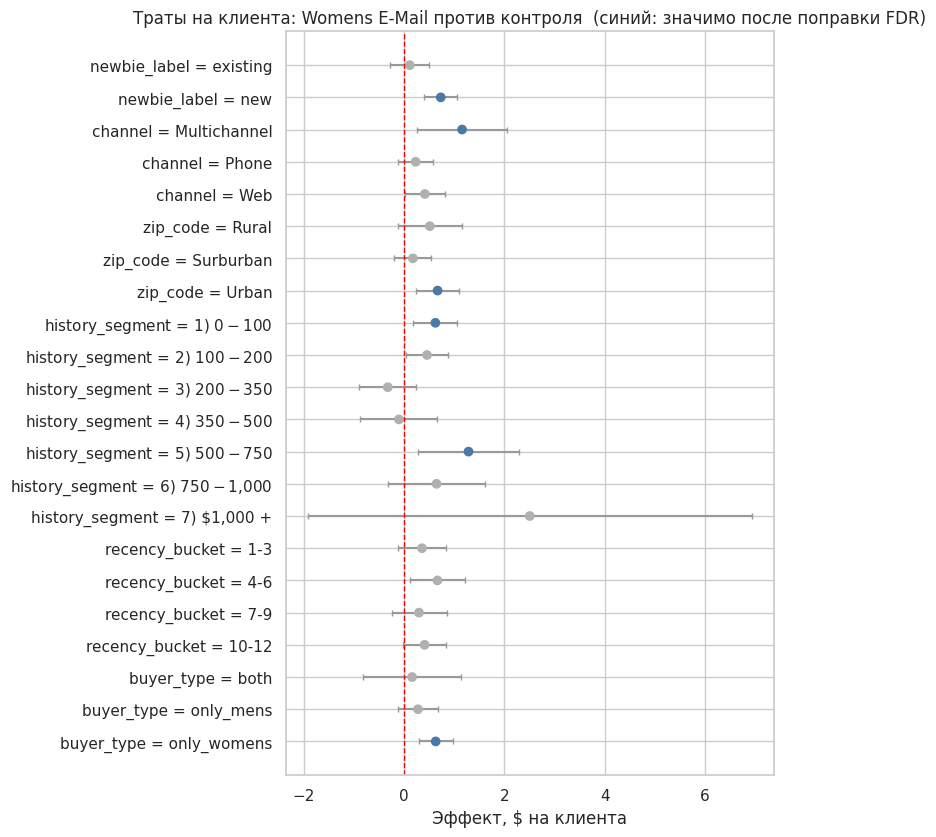

In [11]:
for t in TREATMENTS:
    forest(results[("spend", t)], f"{names['spend']}: {t} против контроля", units["spend"])

## 3. Различаются ли эффекты между сегментами по-настоящему

Графики показывают разброс эффектов, но не отвечают на главный вопрос: **это реальное различие или шум?**
Проверяем формально через логистическую регрессию с взаимодействием «письмо × сегмент» и критерий отношения правдоподобия.

- Нулевая гипотеза: эффект письма одинаков во всех сегментах признака.
- Малый p-value означает, что эффект зависит от сегмента.

In [12]:
def interaction_p(metric, treat, dim):
    d = df[df.segment.isin([treat, CONTROL])].copy()
    d["treated"] = (d.segment == treat).astype(int)
    d[dim] = d[dim].astype(str)
    m0 = smf.logit(f"{metric} ~ treated + C({dim})", d).fit(disp=0)
    m1 = smf.logit(f"{metric} ~ treated * C({dim})", d).fit(disp=0)
    lr = 2 * (m1.llf - m0.llf)
    return stats.chi2.sf(lr, m1.df_model - m0.df_model)

rows = []
for metric in ["visit", "conversion"]:
    for t in TREATMENTS:
        for dim in DIMS:
            rows.append({"метрика": metric, "письмо": t, "признак": dim, "p-value": interaction_p(metric, t, dim)})
inter = pd.DataFrame(rows)
inter["q-value"] = multipletests(inter["p-value"], method="fdr_bh")[1]
inter["эффект зависит от сегмента"] = np.where(inter["q-value"] < 0.05, "да", "нет")
display(inter.pivot_table(index="признак", columns=["метрика", "письмо"], values="q-value"))
display(inter.sort_values("p-value").reset_index(drop=True))

метрика          conversion                     visit              
письмо          Mens E-Mail Womens E-Mail Mens E-Mail Womens E-Mail
признак                                                            
buyer_type           0.8314        0.1802      0.4608        0.0000
channel              0.8325        0.5562      0.2169        0.4910
history_segment      0.8314        0.0874      0.6303        0.2329
newbie_label         0.0830        0.0076      0.0038        0.0007
recency_bucket       0.2329        0.4608      0.4608        0.0766
zip_code             0.5114        0.8775      0.0830        0.0237

,метрика,письмо,признак,p-value,q-value,эффект зависит от сегмента
0,visit,Womens E-Mail,buyer_type,0.0000,0.0000,да
1,visit,Womens E-Mail,newbie_label,0.0001,0.0007,да
2,visit,Mens E-Mail,newbie_label,0.0005,0.0038,да
3,conversion,Womens E-Mail,newbie_label,0.0013,0.0076,да
4,visit,Womens E-Mail,zip_code,0.0049,0.0237,да
5,visit,Womens E-Mail,recency_bucket,0.0191,0.0766,нет
6,conversion,Mens E-Mail,newbie_label,0.0268,0.0830,нет
7,visit,Mens E-Mail,zip_code,0.0277,0.0830,нет
8,conversion,Womens E-Mail,history_segment,0.0328,0.0874,нет
9,conversion,Womens E-Mail,buyer_type,0.0751,0.1802,нет


## 4. Где письмо работает слабо или не работает

Сегменты, где эффект по визитам не отличается от нуля после поправки.

In [13]:
for t in TREATMENTS:
    r = results[("visit", t)]
    weak = r[~r["значимо (FDR 5%)"] | (r["эффект"] <= 0)]
    print(f"{t}: сегментов без значимого эффекта на визиты: {len(weak)} из {len(r)}")
    display(weak[["признак", "сегмент", "n_тест", "эффект", "CI95 низ", "CI95 верх", "q-value"]])

Mens E-Mail: сегментов без значимого эффекта на визиты: 0 из 22


,признак,сегмент,n_тест,эффект,CI95 низ,CI95 верх,q-value


Womens E-Mail: сегментов без значимого эффекта на визиты: 0 из 22


,признак,сегмент,n_тест,эффект,CI95 низ,CI95 верх,q-value


## 5. Какое письмо отправлять кому

Сравниваем два письма друг с другом внутри каждого типа покупателя: логично ожидать, что мужское письмо лучше для тех, кто покупает мужское.

In [14]:
rows = []
for bt, d in df.groupby("buyer_type"):
    m = d[d.segment == "Mens E-Mail"]; w = d[d.segment == "Womens E-Mail"]; c = d[d.segment == CONTROL]
    if min(len(m), len(w), len(c)) < MIN_N:
        continue
    rows.append({
        "buyer_type": bt, "n": len(d),
        "визиты контроль": c.visit.mean() * 100,
        "визиты Mens": m.visit.mean() * 100, "визиты Womens": w.visit.mean() * 100,
        "конверсия контроль": c.conversion.mean() * 100,
        "конверсия Mens": m.conversion.mean() * 100, "конверсия Womens": w.conversion.mean() * 100,
        "траты контроль": c.spend.mean(), "траты Mens": m.spend.mean(), "траты Womens": w.spend.mean(),
    })
display(pd.DataFrame(rows))

,buyer_type,n,визиты контроль,визиты Mens,визиты Womens,конверсия контроль,конверсия Mens,конверсия Womens,траты контроль,траты Mens,траты Womens
0,both,6448,18.0549,31.4993,25.1653,0.9307,2.4301,1.4636,1.1801,3.0051,1.3420
1,only_mens,28818,9.9813,16.8968,11.0892,0.5499,1.1509,0.6132,0.6954,1.3782,0.9738
2,only_womens,28734,9.5808,16.6388,16.9794,0.5148,1.0870,1.0262,0.4906,1.1063,1.1222


## Выводы по сегментному анализу

**1. Мужское письмо (Mens E-Mail) работает на всех клиентов.** Эффект на визиты везде примерно одинаковый, около +7 п.п. (от +6,2 до +9,9 п.п.; исключение — покупавшие и мужское, и женское, см. пункт 4), и значим в каждом из 22 сегментов. Конверсия растёт во всех сегментах; единственное исключение, где интервал включает ноль, это узкая группа с историей покупок от $1 000 (464 клиента), там мало данных. Формальная проверка не показала, что эффект сильно зависит от сегмента: для конверсии все различия незначимы после поправки FDR.

**2. Женское письмо (Womens E-Mail) сильно зависит от того, кому его отправили.**

| Сегмент | Визиты (контроль → письмо) | Конверсия, эффект | Траты, эффект |
|---|---|---|---|
| Покупали только женское | 9,6% → 17,0% (+7,4 п.п.) | +0,51 п.п., значимо | +$0,63, значимо |
| Покупали только мужское | 10,0% → 11,1% (+1,1 п.п.) | +0,06 п.п., не значимо | +$0,28, не значимо |
| Новые клиенты | 7,9% → 12,9% (+5,0 п.п.) | +0,53 п.п., значимо | +$0,73, значимо |
| Существующие клиенты | 13,4% → 17,4% (+4,0 п.п.) | +0,09 п.п., не значимо | +$0,11, не значимо |

Формальная проверка это подтверждает (q-value после FDR): зависимость эффекта на визиты от типа покупателя q < 0,0001, от статуса «новичок» q = 0,0007; зависимость эффекта на конверсию от статуса «новичок» q = 0,0076.
Женское письмо надёжно приводит людей на сайт, но заметно повышает покупки только у новых клиентов и у тех, кто раньше покупал женское. Отсутствие значимого эффекта в остальных сегментах означает «эффекта не обнаружено», а не «эффекта нет»: сегменты небольшие.

**3. Мужское письмо не хуже женского даже для покупательниц женской одежды.** В сегменте «покупали только женское» конверсия 1,09% (Mens) против 1,03% (Womens), визиты 16,6% против 17,0%. Для покупавших мужское и для покупавших и то и другое разница в пользу мужского письма большая: 1,15% против 0,61% и 2,43% против 1,46% по конверсии.

**4. Самый отзывчивый сегмент: покупали и мужское, и женское.** Мужское письмо даёт там +13,4 п.п. визитов и +1,5 п.п. конверсии (0,93% → 2,43%). Это 10% клиентов.

**5. Отрицательных значимых эффектов нет.** Ни в одном сегменте письмо не снизило метрики значимо. У женского письма встречаются отрицательные точечные оценки по конверсии (история $200–500: −0,07 и −0,22 п.п.), но интервалы широко включают ноль.

**Оговорки.**
- Сегменты задавались по известным признакам заранее, но проверок много; поэтому везде применена поправка FDR.
- Формальная проверка идёт через логистическую регрессию, то есть на шкале шансов. Для статуса «новичок» по визитам она значима при очень близких абсолютных эффектах (+7,8 против +7,5 п.п. для мужского письма): это следствие разных базовых уровней (13,4% против 7,9%), а не практическое различие.
- Самые узкие сегменты (больше $750 истории, около 500 клиентов) дают широкие интервалы, их оценки нельзя читать буквально.

**Практический вывод.** Если выбирать одно письмо для всех, то мужское. Женское письмо стоит отправлять только покупавшим женское и новым клиентам: остальным оно почти не приносит покупок. Но это решение по одному признаку за раз. Какие клиенты получат пользу, когда признаки действуют вместе, покажет uplift-модель в следующей части.